In [31]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose

In [32]:
df= pd.read_csv('/Users/Admin/Documents/proyectosAnalisisDatos/Pandas/Data/sales_data_correlated.csv')

display(df.head())

,Order ID,Product,Price Each,Order Date,Purchase Address,Quantity Ordered
0,176633,Flatscreen TV,13.69,2023-01-01,"492 Main St, Phoenix, AZ",4
1,176592,Wired Headphones,13.28,2023-01-02,"910 Main St, Dallas, TX",4
2,176655,Macbook Pro Laptop,14.27,2023-01-03,"345 Main St, Portland, OR",4
3,176586,Flatscreen TV,15.77,2023-01-04,"275 Main St, Los Angeles, CA",3
4,176626,Google Phone,12.30,2023-01-05,"138 Main St, San Francisco, CA",4


In [ ]:
#Transformar la columna 'Order Date' a tipo datetime
#'coerce' = Convierte los valores inválidos en NaT (Not a Time, equivalente a NaN en fechas).
df['Order Date'] = pd.to_datetime(df['Order Date'], errors='coerce')
display(df.dtypes)


Order ID                     int64
Product                     object
Price Each                 float64
Order Date          datetime64[ns]
Purchase Address            object
Quantity Ordered             int64
dtype: object

In [34]:
#Extraer los componentes de fecha
df['Order Year'] = df['Order Date'].dt.year
df['Order Month'] = df['Order Date'].dt.month
df['Order Day'] = df['Order Date'].dt.day
df['Order Day_name'] = df['Order Date'].dt.day_name()
df['Order Hour'] = df['Order Date'].dt.hour
df['Order Minute'] = df['Order Date'].dt.minute
df['Order Second'] = df['Order Date'].dt.second
display(df.head())

,Order ID,Product,Price Each,Order Date,Purchase Address,Quantity Ordered,Order Year,Order Month,Order Day,Order Day_name,Order Hour,Order Minute,Order Second
0,176633,Flatscreen TV,13.69,2023-01-01,"492 Main St, Phoenix, AZ",4,2023,1,1,Sunday,0,0,0
1,176592,Wired Headphones,13.28,2023-01-02,"910 Main St, Dallas, TX",4,2023,1,2,Monday,0,0,0
2,176655,Macbook Pro Laptop,14.27,2023-01-03,"345 Main St, Portland, OR",4,2023,1,3,Tuesday,0,0,0
3,176586,Flatscreen TV,15.77,2023-01-04,"275 Main St, Los Angeles, CA",3,2023,1,4,Wednesday,0,0,0
4,176626,Google Phone,12.30,2023-01-05,"138 Main St, San Francisco, CA",4,2023,1,5,Thursday,0,0,0


In [35]:
#Crear indices temporales
df.set_index('Order Date', inplace=True)
display(df.head())

,Order ID,Product,Price Each,Purchase Address,Quantity Ordered,Order Year,Order Month,Order Day,Order Day_name,Order Hour,Order Minute,Order Second
Order Date,,,,,,,,,,,,
2023-01-01,176633,Flatscreen TV,13.69,"492 Main St, Phoenix, AZ",4,2023,1,1,Sunday,0,0,0
2023-01-02,176592,Wired Headphones,13.28,"910 Main St, Dallas, TX",4,2023,1,2,Monday,0,0,0
2023-01-03,176655,Macbook Pro Laptop,14.27,"345 Main St, Portland, OR",4,2023,1,3,Tuesday,0,0,0
2023-01-04,176586,Flatscreen TV,15.77,"275 Main St, Los Angeles, CA",3,2023,1,4,Wednesday,0,0,0
2023-01-05,176626,Google Phone,12.30,"138 Main St, San Francisco, CA",4,2023,1,5,Thursday,0,0,0


In [36]:
#Remuestreo a nivel mensual
monthly_sales = df['Quantity Ordered'].resample('ME').sum()
print(monthly_sales)

Order Date
2023-01-31    53
2023-02-28    10
2023-03-31     0
2023-04-30     0
Freq: ME, Name: Quantity Ordered, dtype: int64


In [37]:
#Crear intervalos de fechas 
df['Day Since Last Order'] = df.index.to_series().diff().dt.days
display(df[['Day Since Last Order']].head())

,Day Since Last Order
Order Date,
2023-01-01,NaN
2023-01-02,1.0
2023-01-03,1.0
2023-01-04,1.0
2023-01-05,1.0


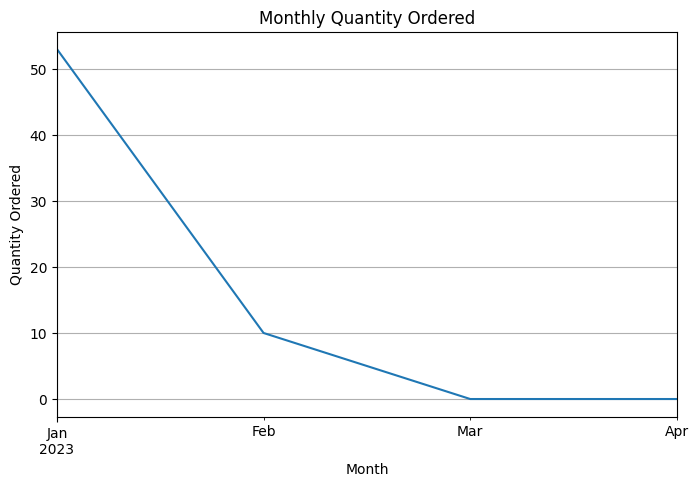

In [38]:
#Graficos de series temporales
plt.figure(figsize=(8,5))
monthly_sales.plot()
plt.title('Monthly Quantity Ordered')
plt.xlabel('Month')
plt.ylabel('Quantity Ordered')
plt.grid()
plt.show()
    


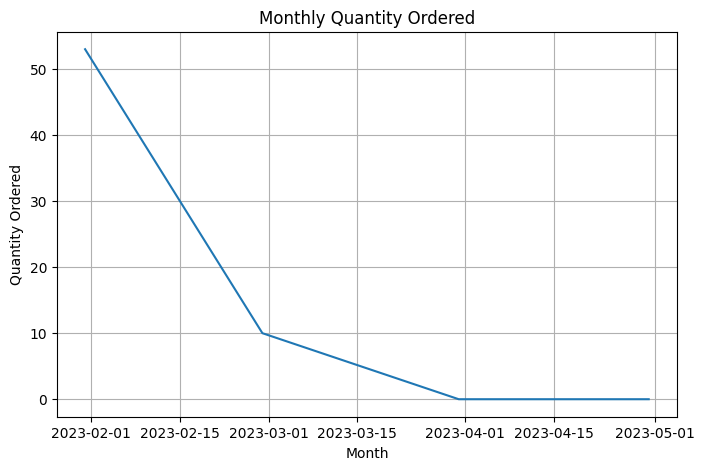

In [39]:
#Graficos de series temporales
plt.figure(figsize=(8,5))
sns.lineplot(data=monthly_sales)
plt.title('Monthly Quantity Ordered')
plt.xlabel('Month')
plt.ylabel('Quantity Ordered')
plt.grid()
plt.show()

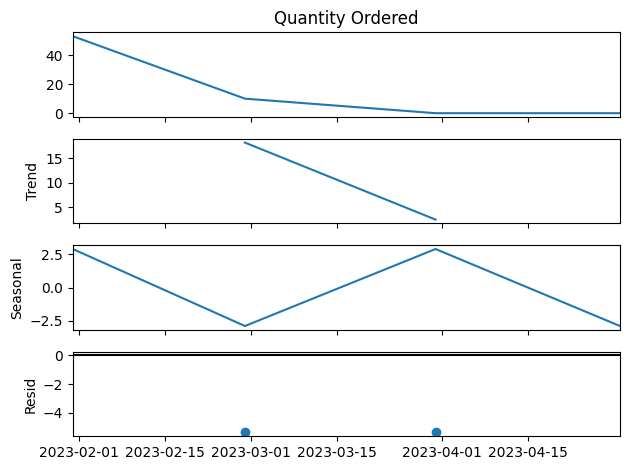

In [44]:
descomposition = seasonal_decompose(monthly_sales, model='additive', period=2)
descomposition.plot()
plt.show()

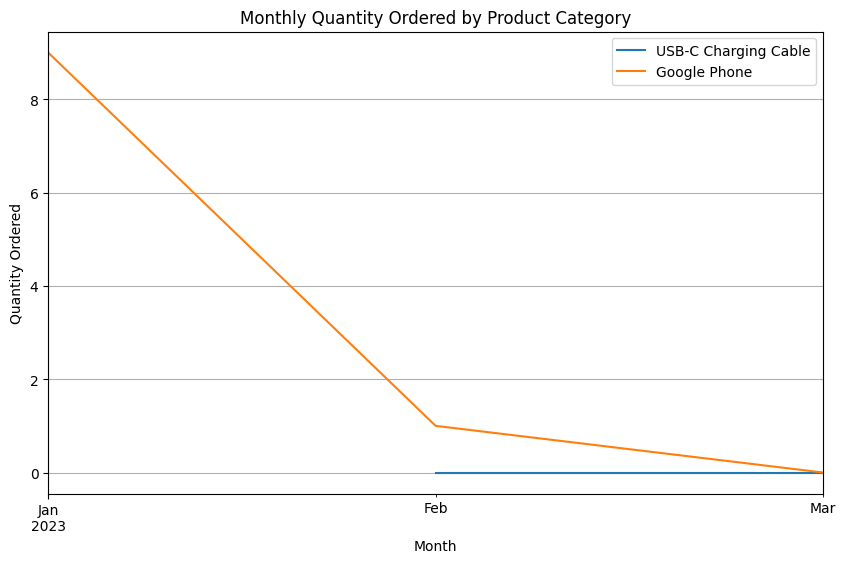

In [47]:
#Graficos de multiples series temporales
plt.figure(figsize=(10,6))
df[df['Product'] == 'USB-C Charging Cable']['Quantity Ordered'].resample('ME').sum().plot(label='USB-C Charging Cable')
df[df['Product'] == 'Google Phone']['Quantity Ordered'].resample('ME').sum().plot(label='Google Phone')
plt.title('Monthly Quantity Ordered by Product Category')
plt.xlabel('Month')
plt.ylabel('Quantity Ordered')
plt.legend()
plt.grid()
plt.show()
